# Forward Prediction: Week *t* → Week *t+1*
Follow-up to `03_baseline_model_testing.ipynb`, the `03_2_baseline_model_tuning_*` notebooks and `02_1_correlation_tests.ipynb`.

**Why this notebook exists.** Every model so far answers *"given this week's numbers, what is this week's status?"* The features and the target come from the **same week**, and rows were split **randomly** (02_2) and scored with **shuffled** folds (03). That classifies a week that has already happened.

`data_comprehension.md` describes a different task: **"Use week (t) to predict week (t+1)."** That is forecasting: at the end of week *t*, say what next week's status will be.

02_1 (section 6) found that the 1- and 2-week lags have almost no *straight-line* correlation with the same-week status. That result still stands, but it is a narrower question. It doesn't show that rows are independent, and it doesn't rule out signal from rolling summaries, changes, or non-linear relationships. This notebook tests forward prediction **directly**.

**What changes compared with 03:**
- **Target:** next week's `route_status`, not this week's.
- **Inputs:** only information available at the end of week *t*.
- **Split:** chronological. The model is trained on earlier weeks and scored on later weeks, never on a random mix.

**The comparison (one model at a time, no new tuning):**

| Row | Inputs | Question it answers |
|---|---|---|
| **A** | the 7 current model features, from week *t* | Do this week's conditions say anything about next week? |
| **B** | A + lag, change and 4-week rolling features | Do recent history and trends add forward-looking signal? |
| **C** | B + week *t*'s own delay and status | Does knowing how this week turned out help predict next week? |
| *no-skill* | none (always predicts the training mix) | What does "no signal at all" score? |
| *same-week (old framing)* | A, predicting the **same** week | How much of the earlier scores came from same-week information? |

Both tuned models from 03_2, **CatBoost** and **LightGBM**, are run, and a rule fixed in advance decides which one is better.

01 to 03 are **not changed**. They remain the same-week benchmark.

## 1. Load Data and Shared Setup
`supply_chain_disruption.csv` from 01 is used instead of `model_ready.csv`, for two reasons:
- row C needs `shipping_delay_days`, which `model_ready.csv` leaves out;
- `model_ready.csv` carries 02_2's **random** `split` column, which must not be used here.

Rows are sorted by route number, then date (same as 02_2). The scoring helpers come from `tuning_setup.py`, so scores are computed exactly as in 03_2.

In [1]:
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, f1_score, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight

from tuning_setup import DISRUPTED, STATUS_ORDER, STATUS_TO_NUMBER, choose_threshold, score_predictions

df = pd.read_csv("../data/preprocessed/supply_chain_disruption.csv")
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")

# Sort by route number (R1, R2, ..., R50), then by date
route_number = df["route_id"].str.lstrip("R").astype(int)
df = (df.assign(route_number=route_number)
        .sort_values(["route_number", "date"])
        .drop(columns="route_number")
        .reset_index(drop=True))

print("Shape:", df.shape)

Shape: (31300, 48)


### Check: Every Route Has Every Week
`shift` and `rolling` below move by **rows**. That only means "by weeks" if every route has every week, in order, with no gaps. If a week were missing, "last week" would silently become "two weeks ago".

In [2]:
weeks_per_route = df.groupby("route_id")["date"].nunique()
gaps = df.groupby("route_id")["date"].diff().dropna()

assert df["route_id"].nunique() == 50 and df["date"].nunique() == 626 and len(df) == 50 * 626
assert (weeks_per_route == 626).all()
assert (gaps == pd.Timedelta(days=7)).all(), "A route has a missing or repeated week"
print(f"{df['route_id'].nunique()} routes x {df['date'].nunique()} weeks, every step is exactly 7 days "
      f"({df['date'].min().date()} to {df['date'].max().date()})")

50 routes x 626 weeks, every step is exactly 7 days (2015-01-04 to 2026-12-27)


## 2. Build the Target and the Historical Features
Everything is computed **per route** (`groupby("route_id")`), so one route's values never leak into another's.

**Target:** each row (route, week *t*) gets the status of the **next** week of the same route (`shift(-1)`), plus that week's date (`target_date`). Each route's last week has no next week, so its target is empty and the row is dropped later.

**Historical features**, for the 3 main signals (`port_congestion_index`, `weather_disruption_score`, `geopolitical_risk_score`):

| Feature | Meaning | Weeks used |
|---|---|---|
| `_lag1` | last week's value | *t-1* |
| `_delta1` | change from last week (this week − last week) | *t-1*, *t* |
| `_roll4_mean` | average of the last 4 weeks | *t-3* to *t* |
| `_roll4_max` | highest value in the last 4 weeks | *t-3* to *t* |

The rolling windows **end at week *t*** and include it, which is fine: week *t* is over when the forecast for *t+1* is made. `min_periods=2` gives a value from the second week of each route onward.

**Row C extras:** `shipping_delay_days` and `status_t` (week *t*'s status as 0/1/2). Both are known once week *t* is over. `data_comprehension.md` only rules them out for predicting the **same** week.

All of this is in one function, so section 3 can re-run it on cut-off data to prove nothing looks forward.

In [3]:
route_col, time_col, target_col = "route_id", "date", "route_status"

signal_cols = [
    "port_congestion_index",
    "weather_disruption_score",
    "geopolitical_risk_score",
]

def add_forward_columns(data):
    """Next week's status as the target, plus historical features built only from week t and earlier.

    Expects rows sorted by route, then date (checked in section 1).
    """
    data = data.copy()
    by_route = data.groupby(route_col)

    # Information available in week t predicts status in week t+1
    data["target_next_week"] = by_route[target_col].shift(-1)
    data["target_date"] = by_route[time_col].shift(-1)

    for col in signal_cols:
        values = by_route[col]
        data[f"{col}_lag1"] = values.shift(1)
        data[f"{col}_delta1"] = values.diff()
        data[f"{col}_roll4_mean"] = values.transform(lambda s: s.rolling(4, min_periods=2).mean())
        data[f"{col}_roll4_max"] = values.transform(lambda s: s.rolling(4, min_periods=2).max())

    # Week t's own outcome: known once week t is over
    data["status_t"] = data[target_col].map(STATUS_TO_NUMBER)
    return data

forward_df = add_forward_columns(df)

# The target is always exactly the next week of the same route
has_target = forward_df["target_date"].notna()
assert (forward_df.loc[has_target, "target_date"] - forward_df.loc[has_target, "date"] == pd.Timedelta(days=7)).all()

forward_df[["route_id", "date", "route_status", "target_date", "target_next_week",
            "geopolitical_risk_score", "geopolitical_risk_score_lag1", "geopolitical_risk_score_roll4_mean"]].head(6)

,route_id,date,route_status,target_date,target_next_week,geopolitical_risk_score,geopolitical_risk_score_lag1,geopolitical_risk_score_roll4_mean
0,R1,2015-01-04,Delayed,2015-01-11,Delayed,57.15,NaN,NaN
1,R1,2015-01-11,Delayed,2015-01-18,Normal,41.47,57.15,49.310000
2,R1,2015-01-18,Normal,2015-01-25,Delayed,79.69,41.47,59.436667
3,R1,2015-01-25,Delayed,2015-02-01,Delayed,67.15,79.69,61.365000
4,R1,2015-02-01,Delayed,2015-02-08,Delayed,7.59,67.15,48.975000
5,R1,2015-02-08,Delayed,2015-02-15,Delayed,83.86,7.59,59.572500


### Feature Sets
**A** is the 7-feature set the current models use (`model_ready.csv`), now taken from week *t*. **B** adds the 12 historical features. **C** adds week *t*'s delay and status.

In [4]:
features_A = [
    "geopolitical_risk_score", "port_congestion_index", "weather_disruption_score",
    "origin_active_event_risk", "destination_active_event_risk",
    "covid_supply_shock_active", "russia_ukraine_war_active",
]
historical_features = [f"{col}_{kind}" for col in signal_cols for kind in ["lag1", "delta1", "roll4_mean", "roll4_max"]]
features_B = features_A + historical_features
features_C = features_B + ["shipping_delay_days", "status_t"]

feature_sets = {"A": features_A, "B": features_B, "C": features_C}
for name, columns in feature_sets.items():
    print(f"{name} ({len(columns)}): {', '.join(columns)}")

A (7): geopolitical_risk_score, port_congestion_index, weather_disruption_score, origin_active_event_risk, destination_active_event_risk, covid_supply_shock_active, russia_ukraine_war_active
B (19): geopolitical_risk_score, port_congestion_index, weather_disruption_score, origin_active_event_risk, destination_active_event_risk, covid_supply_shock_active, russia_ukraine_war_active, port_congestion_index_lag1, port_congestion_index_delta1, port_congestion_index_roll4_mean, port_congestion_index_roll4_max, weather_disruption_score_lag1, weather_disruption_score_delta1, weather_disruption_score_roll4_mean, weather_disruption_score_roll4_max, geopolitical_risk_score_lag1, geopolitical_risk_score_delta1, geopolitical_risk_score_roll4_mean, geopolitical_risk_score_roll4_max
C (21): geopolitical_risk_score, port_congestion_index, weather_disruption_score, origin_active_event_risk, destination_active_event_risk, covid_supply_shock_active, russia_ukraine_war_active, port_congestion_index_lag1, p

## 3. Check: No Feature Looks Into the Future
If a feature secretly used later weeks, the model would look better than it can be in real use. The test below:
1. cuts the data off at 2020-01-05, as if that were "today";
2. rebuilds every feature from the cut-off data only;
3. checks that every feature up to that date is **identical** to the version built from the full data.

A feature that used any week after the cut-off would change, and the check would fail. (The target is excluded, because it uses next week's status on purpose.)

In [5]:
cutoff_check_date = pd.Timestamp("2020-01-05")
history_only = add_forward_columns(df[df["date"] <= cutoff_check_date])
full_history = forward_df[forward_df["date"] <= cutoff_check_date]

input_columns = sorted(set(features_C))
pd.testing.assert_frame_equal(history_only[input_columns].reset_index(drop=True),
                              full_history[input_columns].reset_index(drop=True))
print(f"All {len(input_columns)} input columns up to {cutoff_check_date.date()} are identical with or without later data.")

All 21 input columns up to 2020-01-05 are identical with or without later data.


## 4. Chronological Split
The split follows the **week being predicted** (`target_date`), so all routes of a target week stay on the same side:
- **train:** target weeks before the cutoff (the first 80% of target weeks);
- **test:** target weeks from the cutoff on (the last 20%).

The model is always scored on weeks that come **after** everything it learned from, which is how it would be used.

**Same rows for every row of the comparison:** rows without a target (each route's last week) or without a historical feature (each route's first week) are dropped up front. A, B, C and the references are then trained and scored on exactly the same rows, so differences come from the features alone.

**Validation block:** the last 20% of the *training* target weeks. It is used **only** to choose the Disrupted threshold and to pick between CatBoost and LightGBM. The test set is never used to make a choice.

In [6]:
# Manager's cutoff: 80% of target weeks (computed before any rows are dropped)
target_weeks = np.sort(forward_df["target_date"].dropna().unique())
cutoff = pd.Timestamp(target_weeks[int(0.8 * len(target_weeks))])

# Same rows for every variant
model_df = forward_df.dropna(subset=["target_next_week"] + features_C).reset_index(drop=True)
model_df["y_next"] = model_df["target_next_week"].map(STATUS_TO_NUMBER).astype(int)
model_df["y_same"] = model_df["status_t"].astype(int)      # only for the same-week reference row

train_df = model_df[model_df["target_date"] < cutoff].reset_index(drop=True)
test_df = model_df[model_df["target_date"] >= cutoff].reset_index(drop=True)

# Validation block: last 20% of the training target weeks
train_weeks = np.sort(train_df["target_date"].unique())
validation_start = pd.Timestamp(train_weeks[int(0.8 * len(train_weeks))])
inner_train_df = train_df[train_df["target_date"] < validation_start].reset_index(drop=True)
validation_df = train_df[train_df["target_date"] >= validation_start].reset_index(drop=True)

assert not set(train_df["target_date"]) & set(test_df["target_date"])
assert not set(inner_train_df["target_date"]) & set(validation_df["target_date"])

print("Cutoff (first test target week):", cutoff.date())
print("Validation block starts:", validation_start.date())

def describe(name, part):
    mix = part["target_next_week"].value_counts(normalize=True).reindex(STATUS_ORDER) * 100
    return {"set": name, "rows": len(part), "target weeks": part["target_date"].nunique(),
            "first target week": part["target_date"].min().date(), "last target week": part["target_date"].max().date(),
            **{f"{status} %": round(mix[status], 1) for status in STATUS_ORDER}}

pd.DataFrame([describe("train (all)", train_df), describe("  inner train", inner_train_df),
              describe("  validation", validation_df), describe("test", test_df)]).set_index("set")

Cutoff (first test target week): 2024-08-11
Validation block starts: 2022-09-11


,rows,target weeks,first target week,last target week,Normal %,Delayed %,Disrupted %
set,,,,,,,
train (all),24950,499,2015-01-18,2024-08-04,33.4,64.1,2.5
inner train,19950,399,2015-01-18,2022-09-04,33.2,64.2,2.5
validation,5000,100,2022-09-11,2024-08-04,34.1,63.7,2.2
test,6250,125,2024-08-11,2026-12-27,30.3,63.7,6.1


### Reading the Split
- **Disrupted is more than twice as common in the test weeks as in training.** All 30 high-disruption weeks that 01 found (from 2026-06-07) fall in the test period, and the model never saw that period during training. This is a harder test than a random split, and also a more realistic one.
- Because of this shift, scores must be read against the **test** Disrupted rate. A model with no skill gets a Disrupted PR-AUC about equal to that rate, not the ~0.03 seen in 03.

## 5. Models
Both tuned models from 03_2, with the settings saved in `results/tuning/<model>/best_params.json`, built **the same way as in 03_2**:
- **CatBoost:** balanced `class_weights` (computed from the rows it is trained on), `random_seed=42`
- **LightGBM:** `class_weight="balanced"`, `subsample_freq=1`, `random_state=42`

**No new tuning.** These settings were tuned for the same-week task on 7 features, so they are not ideal for B and C. Both models carry the same handicap, and the manager asked for a direct comparison, not a new model search.

**Steps for each model and each feature set:**
1. Train on the inner-train weeks and predict the validation block, then **choose the Disrupted threshold** there (`choose_threshold`, the macro-F1 rule used in 03_2).
2. Retrain on **all** training weeks and predict the test weeks.
3. Score the test weeks with the default rule (highest probability wins) **and** with the threshold from step 1.

In [7]:
def load_params(folder):
    with open(f"../results/tuning/{folder}/best_params.json") as f:
        return json.load(f)["params"]

catboost_params = load_params("catboost")
lightgbm_params = load_params("lightgbm")

def make_model(model_name, y_fit):
    """A fresh model with the tuned settings from 03_2, set up exactly as 03_2 does."""
    if model_name == "CatBoost":
        class_weights = tuple(float(w) for w in compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=y_fit))
        return CatBoostClassifier(**catboost_params, class_weights=class_weights, thread_count=-1, random_seed=42,
                                  verbose=0, allow_writing_files=False)
    if model_name == "LightGBM":
        return LGBMClassifier(**lightgbm_params, class_weight="balanced", subsample_freq=1, n_jobs=-1,
                              random_state=42, verbose=-1)
    if model_name == "no-skill":
        return DummyClassifier(strategy="prior")
    raise ValueError(model_name)

model_names = ["CatBoost", "LightGBM"]
print("CatBoost:", catboost_params)
print("LightGBM:", lightgbm_params)

CatBoost: {'bagging_temperature': 0.22649577519793795, 'border_count': 254, 'depth': 6, 'iterations': 688, 'l2_leaf_reg': 10.485733570643786, 'learning_rate': 0.03726104236509947, 'random_strength': 7.472397689332939}
LightGBM: {'colsample_bytree': 0.6955303037866204, 'learning_rate': 0.009793166754027884, 'max_depth': 6, 'min_child_samples': 6, 'n_estimators': 1121, 'num_leaves': 9, 'reg_alpha': 0.00678838791242122, 'reg_lambda': 0.18655260217376832, 'subsample': 0.5156566462277793}


## 6. Decision Rules (Fixed Before Looking at the Results)
These rules are written down **before** the results, so the outcome can't be bent to fit what we hoped to see.

**Does a feature set help?** B is "better than A" only if, on the test weeks:
- the 95% confidence interval for the change in **Disrupted PR-AUC** (B − A) is entirely **above 0**, and
- the 95% interval for the change in **macro-F1** is **not entirely below 0** (B must not clearly hurt the overall score).

If instead the Disrupted PR-AUC interval is entirely **below 0**, the verdict is "worse". Anything else is "no clear difference", and the simpler set (A) is preferred. C vs B uses the same rule.

**CatBoost or LightGBM?**
- The pick is the model with the higher **Disrupted PR-AUC on the validation block** (never the test set).
- The test set then **confirms** it only if the 95% interval for (picked − other) on the test weeks is entirely above 0.
- If not, the verdict is "no meaningful difference", and LightGBM is preferred because it trains faster.

**Why Disrupted PR-AUC leads:** Disrupted is the status we most want to warn about, and PR-AUC doesn't depend on a threshold. A threshold chosen on earlier weeks can sit in the wrong place once the Disrupted rate changes, as it does in the test weeks.

**Confidence intervals:** a single test period gives a single number, so section 8 resamples **whole test weeks** (1,000 times, with replacement) and recomputes every score. The same resampled weeks are used for every model and feature set, so differences are compared fairly ("paired"). Keeping whole weeks together matters because the 50 routes of a week share the same conditions.

## 7. Train and Score
For each model and each feature set (plus the two reference rows), this cell runs the 3 steps from section 5. It keeps:
- the test probabilities, used for the confidence intervals, the period breakdown and the saved results;
- the validation-block scores, used to pick the model;
- the fitted test models, used for feature importance.

In [8]:
def fit(model_name, X, y):
    return make_model(model_name, y).fit(X, y)

runs = []                       # (row label, model name, feature list, target column)
for model_name in model_names:
    for set_name, columns in feature_sets.items():
        runs.append((set_name, model_name, columns, "y_next"))
    runs.append(("same-week (old framing)", model_name, features_A, "y_same"))
runs.append(("no-skill", "no-skill", features_A, "y_next"))

test_probabilities, validation_scores, test_models, result_rows = {}, {}, {}, []
for row_label, model_name, columns, target in runs:
    key = (row_label, model_name)

    # Step 1: threshold (and model choice scores) from the validation block
    validation_model = fit(model_name, inner_train_df[columns], inner_train_df[target])
    validation_probabilities = validation_model.predict_proba(validation_df[columns])
    threshold = None if model_name == "no-skill" else choose_threshold(validation_df[target], validation_probabilities)
    validation_scores[key] = score_predictions(validation_df[target], validation_probabilities)

    # Step 2: retrain on all training weeks, predict the test weeks
    test_model = fit(model_name, train_df[columns], train_df[target])
    probabilities = test_model.predict_proba(test_df[columns])
    test_probabilities[key], test_models[key] = probabilities, test_model

    # Step 3: score with the default rule and with the validation threshold
    default_scores = score_predictions(test_df[target], probabilities)
    threshold_scores = score_predictions(test_df[target], probabilities, threshold) if threshold is not None else default_scores
    result_rows.append({
        "row": row_label, "model": model_name, "features": len(columns),
        "macro_f1": default_scores["macro_f1"],
        "macro_f1 (threshold)": threshold_scores["macro_f1"],
        "threshold": threshold,
        "f1_normal": default_scores["f1_normal"], "f1_delayed": default_scores["f1_delayed"],
        "f1_disrupted (threshold)": threshold_scores["f1_disrupted"],
        "disrupted_precision (threshold)": threshold_scores["disrupted_precision"],
        "disrupted_recall (threshold)": threshold_scores["disrupted_recall"],
        "disrupted_pr_auc": default_scores["disrupted_pr_auc"],
        "roc_auc_ovr": default_scores["roc_auc_ovr"],
    })
    print(f"done: {model_name:9s} {row_label}")

row_order = ["no-skill", "A", "B", "C", "same-week (old framing)"]
results_df = pd.DataFrame(result_rows)
results_df["row"] = pd.Categorical(results_df["row"], row_order, ordered=True)
results_df = results_df.sort_values(["model", "row"]).set_index(["model", "row"])

test_disrupted_rate = (test_df["y_next"] == DISRUPTED).mean()
print(f"\nTest Disrupted rate (= no-skill Disrupted PR-AUC): {test_disrupted_rate:.3f}")
results_df.round(3)

done: CatBoost  A


done: CatBoost  B


done: CatBoost  C


done: CatBoost  same-week (old framing)


done: LightGBM  A


done: LightGBM  B


done: LightGBM  C


done: LightGBM  same-week (old framing)
done: no-skill  no-skill

Test Disrupted rate (= no-skill Disrupted PR-AUC): 0.061


features  macro_f1  macro_f1 (threshold)  \
model    row                                                                 
CatBoost A                               7     0.307                 0.332   
         B                              19     0.313                 0.314   
         C                              21     0.319                 0.322   
         same-week (old framing)         7     0.559                 0.584   
LightGBM A                               7     0.308                 0.338   
         B                              19     0.303                 0.310   
         C                              21     0.305                 0.316   
         same-week (old framing)         7     0.560                 0.579   
no-skill no-skill                        7     0.259                 0.259   

                                  threshold  f1_normal  f1_delayed  \
model    row                                                         
CatBoost A                             0.46      0.324       0.497   
         B                             0.36      0.347       0.532   
         C                             0.35      0.362       0.539   
         same-week (old framing)       0.80      0.675       0.666   
LightGBM A                             0.41      0.323       0.505   
         B                             0.45      0.342       0.502   
         C                             0.44      0.346       0.509   
         same-week (old framing)       0.85      0.676       0.657   
no-skill no-skill                       NaN      0.000       0.778   

                                  f1_disrupted (threshold)  \
model    row                                                 
CatBoost A                                           0.059   
         B                                           0.050   
         C                                           0.058   
         same-week (old framing)                     0.319   
LightGBM A                                           0.085   
         B                                           0.009   
         C                                           0.017   
         same-week (old framing)                     0.295   
no-skill no-skill                                    0.000   

                                  disrupted_precision (threshold)  \
model    row                                                        
CatBoost A                                                  0.088   
         B                                                  0.044   
         C                                                  0.048   
         same-week (old framing)                            0.369   
LightGBM A                                                  0.080   
         B                                                  0.022   
         C                                                  0.038   
         same-week (old framing)                            0.422   
no-skill no-skill                                           0.000   

                                  disrupted_recall (threshold)  \
model    row                                                     
CatBoost A                                               0.045   
         B                                               0.058   
         C                                               0.071   
         same-week (old framing)                         0.281   
LightGBM A                                               0.090   
         B                                               0.005   
         C                                               0.011   
         same-week (old framing)                         0.227   
no-skill no-skill                                        0.000   

                                  disrupted_pr_auc  roc_auc_ovr  
model    row                                                     
CatBoost A                                   0.063        0.479  
         B                          

**Columns:** `macro_f1`, `f1_normal`, `f1_delayed`, `disrupted_pr_auc` and `roc_auc_ovr` use the default rule (or no threshold at all). The columns marked *(threshold)* use the Disrupted threshold chosen on the validation block.

### Reading the Results
- **The same-week reference reproduces the earlier work.** Predicting the **same** week, the models score about 0.58 macro-F1 (with threshold), 0.31 Disrupted PR-AUC and 0.82 ROC-AUC. That is close to the 03_2 cross-validation results (about 0.61 / 0.33 / 0.84), even with a chronological split and a harder test period. The setup works, so the rows below differ because of the target alone.
- **Predicting next week, every row is at the no-skill level.**
  - Disrupted PR-AUC is 0.049 to 0.063, against a test Disrupted rate of 0.061, which is what a model with no information scores.
  - ROC-AUC is 0.47 to 0.48, where 0.5 means guessing. Section 10 explains why it dips slightly below 0.5.
- **macro-F1 of about 0.31 is above the no-skill row (0.26), but that is not skill.** The no-skill row always predicts Delayed. The next cell shows that a shuffled version of each model's predictions scores the same.
- **The threshold doesn't help.** Thresholds chosen on the validation block (0.35 to 0.46) catch only 0.5 to 9% of next week's disruptions, at 2 to 9% precision.

### Is a macro-F1 of about 0.31 Better Than Chance?
The no-skill row always predicts Delayed, so it scores 0 on Normal and Disrupted. A model that spreads its guesses over all 3 statuses gets a higher macro-F1 even with **no** information. To measure chance fairly, each model's predicted statuses are **shuffled** against the true statuses 200 times. This keeps the same mix of predictions but removes any link to the truth.

In [9]:
rng_chance = np.random.default_rng(0)
y_next_test = test_df["y_next"].to_numpy()

chance_rows = []
for model_name in model_names:
    for set_name in feature_sets:
        predictions = test_probabilities[(set_name, model_name)].argmax(axis=1)
        shuffled = [f1_score(y_next_test, rng_chance.permutation(predictions), average="macro") for _ in range(200)]
        low, high = np.percentile(shuffled, [2.5, 97.5])
        chance_rows.append({"model": model_name, "row": set_name,
                            "macro_f1 (model)": f1_score(y_next_test, predictions, average="macro"),
                            "macro_f1 (shuffled, mean)": np.mean(shuffled),
                            "shuffled 95% range": f"[{low:.3f}, {high:.3f}]"})
pd.DataFrame(chance_rows).set_index(["model", "row"]).round(3)

macro_f1 (model)  macro_f1 (shuffled, mean) shuffled 95% range
model    row                                                                
CatBoost A               0.307                      0.306     [0.296, 0.315]
         B               0.313                      0.323     [0.312, 0.336]
         C               0.319                      0.323     [0.314, 0.333]
LightGBM A               0.308                      0.304     [0.294, 0.314]
         B               0.303                      0.315     [0.305, 0.327]
         C               0.305                      0.316     [0.306, 0.327]

**No model's macro-F1 is above the range of its shuffled predictions.** Four are inside it, and LightGBM B and C are slightly *below* it. The predicted statuses carry no information about next week's real status. The extra macro-F1 over the no-skill row comes only from guessing all 3 statuses instead of always guessing Delayed.

## 8. Are the Differences Real?
Paired confidence intervals from resampling whole test weeks (see section 6). Each row is a difference between two of the fitted models, for example "B − A" for CatBoost. An interval that includes 0 means the test weeks can't tell the two apart.

In [10]:
n_resamples = 1000
rng = np.random.default_rng(42)

test_week_values = np.sort(test_df["target_date"].unique())
rows_by_week = [np.flatnonzero(test_df["target_date"].to_numpy() == week) for week in test_week_values]
resampled_weeks = rng.integers(0, len(test_week_values), size=(n_resamples, len(test_week_values)))

y_same_test = test_df["y_same"].to_numpy()

def scores_for(probabilities, y, rows):
    y_part, p_part = y[rows], probabilities[rows]
    return (average_precision_score(y_part == DISRUPTED, p_part[:, DISRUPTED]),
            f1_score(y_part, p_part.argmax(axis=1), average="macro"),
            roc_auc_score(y_part, p_part, multi_class="ovr", average="macro"))

model_keys = [key for key in test_probabilities if key[1] != "no-skill"]
bootstrap = {key: np.empty((n_resamples, 3)) for key in model_keys}
for i, weeks in enumerate(resampled_weeks):
    rows = np.concatenate([rows_by_week[w] for w in weeks])
    for key in model_keys:
        y = y_same_test if key[0] == "same-week (old framing)" else y_next_test
        bootstrap[key][i] = scores_for(test_probabilities[key], y, rows)

comparisons = []
for model_name in model_names:
    comparisons += [(f"{model_name}: B - A", ("B", model_name), ("A", model_name)),
                    (f"{model_name}: C - B", ("C", model_name), ("B", model_name)),
                    (f"{model_name}: C - A", ("C", model_name), ("A", model_name))]
for set_name in feature_sets:
    comparisons.append((f"{set_name}: CatBoost - LightGBM", (set_name, "CatBoost"), (set_name, "LightGBM")))

score_names = ["disrupted_pr_auc", "macro_f1", "roc_auc_ovr"]
delta_rows = []
for label, first, second in comparisons:
    differences = bootstrap[first] - bootstrap[second]
    row = {"comparison": label}
    for j, score_name in enumerate(score_names):
        observed = scores_for(test_probabilities[first], y_next_test, np.arange(len(test_df)))[j] - \
                   scores_for(test_probabilities[second], y_next_test, np.arange(len(test_df)))[j]
        low, high = np.percentile(differences[:, j], [2.5, 97.5])
        row[f"{score_name} change"] = observed
        row[f"{score_name} 95% CI"] = f"[{low:+.3f}, {high:+.3f}]"
        row[f"_{score_name}_low"], row[f"_{score_name}_high"] = low, high
    delta_rows.append(row)

deltas_df = pd.DataFrame(delta_rows).set_index("comparison")

def verdict(row):
    if row["_disrupted_pr_auc_low"] > 0 and not row["_macro_f1_high"] < 0:
        return "better"
    if row["_disrupted_pr_auc_high"] < 0:
        return "worse"
    return "no clear difference"

deltas_df["verdict (section 6 rule)"] = deltas_df.apply(verdict, axis=1)
visible_columns = [c for c in deltas_df.columns if not c.startswith("_")]
deltas_df[visible_columns].round(3)

,disrupted_pr_auc change,disrupted_pr_auc 95% CI,macro_f1 change,macro_f1 95% CI,roc_auc_ovr change,roc_auc_ovr 95% CI,verdict (section 6 rule)
comparison,,,,,,,
CatBoost: B - A,-0.008,"[-0.021, -0.000]",0.005,"[-0.010, +0.022]",0.004,"[-0.012, +0.020]",worse
CatBoost: C - B,-0.002,"[-0.006, +0.001]",0.007,"[-0.003, +0.016]",-0.010,"[-0.018, -0.003]",no clear difference
CatBoost: C - A,-0.011,"[-0.023, -0.003]",0.012,"[-0.004, +0.028]",-0.007,"[-0.022, +0.008]",worse
LightGBM: B - A,-0.012,"[-0.026, -0.004]",-0.005,"[-0.019, +0.010]",-0.012,"[-0.027, +0.003]",worse
LightGBM: C - B,-0.001,"[-0.002, +0.001]",0.001,"[-0.006, +0.009]",-0.001,"[-0.006, +0.005]",no clear difference
LightGBM: C - A,-0.013,"[-0.027, -0.004]",-0.003,"[-0.018, +0.011]",-0.013,"[-0.029, +0.002]",worse
A: CatBoost - LightGBM,0.000,"[-0.010, +0.010]",-0.001,"[-0.011, +0.009]",-0.001,"[-0.009, +0.008]",no clear difference
B: CatBoost - LightGBM,0.004,"[+0.001, +0.009]",0.009,"[-0.001, +0.021]",0.015,"[+0.005, +0.025]",better
C: CatBoost - LightGBM,0.003,"[-0.000, +0.006]",0.015,"[+0.005, +0.025]",0.006,"[-0.003, +0.014]",no clear difference


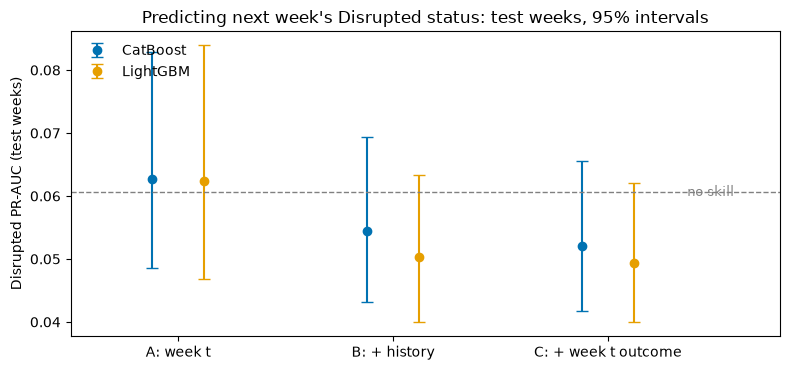

In [11]:
# Disrupted PR-AUC on the test weeks: point = full test period, bar = 95% interval from the resampled weeks
labels = ["A", "B", "C"]
fig, ax = plt.subplots(figsize=(8, 3.8))
for offset, (model_name, color) in zip([-0.12, 0.12], zip(model_names, ["#0072B2", "#E69F00"])):
    for i, set_name in enumerate(labels):
        key = (set_name, model_name)
        point = results_df.loc[(model_name, set_name), "disrupted_pr_auc"]
        low, high = np.percentile(bootstrap[key][:, 0], [2.5, 97.5])
        ax.errorbar(i + offset, point, yerr=[[point - low], [high - point]], fmt="o", color=color, capsize=4,
                    label=model_name if i == 0 else None)
ax.axhline(test_disrupted_rate, color="gray", ls="--", lw=1)
ax.text(2.35, test_disrupted_rate, " no skill", color="gray", va="center", fontsize=9)
ax.set_xticks(range(len(labels)), ["A: week t", "B: + history", "C: + week t outcome"])
ax.set_xlim(-0.5, 2.8)
ax.set_ylabel("Disrupted PR-AUC (test weeks)")
ax.set_title("Predicting next week's Disrupted status: test weeks, 95% intervals")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

### Reading the Differences
- **The historical features don't help, and they make Disrupted PR-AUC slightly worse.** B − A is −0.008 for CatBoost and −0.012 for LightGBM. Both intervals are below 0 (CatBoost's only just), so the section 6 verdict is "worse". macro-F1 doesn't change (both intervals include 0). Section 10 shows why the history features hurt rather than just add nothing.
- **Knowing how this week turned out (C vs B) makes no clear difference.** This fits 02_1, where this week's status and last week's status had a correlation of only about 0.02.
- **In the chart, every A/B/C point sits on or below the no-skill line.** A is a hair above it (0.062 to 0.063 vs 0.061), and B and C are below it. Each point's own interval is wide and crosses the no-skill line, so none is distinguishable from guessing. The *differences* in the table are measured much more precisely, because they compare the same resampled weeks.

## 9. CatBoost or LightGBM?
The rule from section 6: pick the model with the higher Disrupted PR-AUC on the **validation block**, then check on the test weeks whether the difference is clearly real.

In [12]:
choice_rows = []
for set_name in feature_sets:
    validation_pr_auc = {m: validation_scores[(set_name, m)]["disrupted_pr_auc"] for m in model_names}
    picked = max(validation_pr_auc, key=validation_pr_auc.get)
    other = [m for m in model_names if m != picked][0]
    test_row = deltas_df.loc[f"{set_name}: CatBoost - LightGBM"]
    sign = 1 if picked == "CatBoost" else -1
    low, high = sorted([sign * test_row["_disrupted_pr_auc_low"], sign * test_row["_disrupted_pr_auc_high"]])
    confirmed = low > 0
    choice_rows.append({
        "feature set": set_name,
        "validation PR-AUC CatBoost": validation_pr_auc["CatBoost"],
        "validation PR-AUC LightGBM": validation_pr_auc["LightGBM"],
        "picked on validation": picked,
        f"test PR-AUC (picked - other)": sign * test_row["disrupted_pr_auc change"],
        "test 95% CI": f"[{low:+.3f}, {high:+.3f}]",
        "verdict": f"{picked} confirmed" if confirmed else "no meaningful difference -> LightGBM (faster)",
    })

choice_df = pd.DataFrame(choice_rows).set_index("feature set")
choice_df.round(3)

,validation PR-AUC CatBoost,validation PR-AUC LightGBM,picked on validation,test PR-AUC (picked - other),test 95% CI,verdict
feature set,,,,,,
A,0.025,0.021,CatBoost,0.000,"[-0.010, +0.010]",no meaningful difference -> LightGBM (faster)
B,0.025,0.024,CatBoost,0.004,"[+0.001, +0.009]",CatBoost confirmed
C,0.024,0.022,CatBoost,0.003,"[-0.000, +0.006]",no meaningful difference -> LightGBM (faster)


### Reading the Model Choice
- **By the rule, the validation block picks CatBoost for all 3 feature sets.** However, the validation PR-AUCs (0.021 to 0.025) are themselves at the validation Disrupted rate (0.022, section 10), so this is a choice between two models that both have no signal.
- **The test weeks "confirm" CatBoost only for B, and only by 0.004 PR-AUC.** Both B models score **below** no-skill. For A and C, the test weeks show no meaningful difference.
- **Bottom line: for predicting next week, neither model is actually better, because neither finds anything to predict with.** The difference is noise between two no-skill models. For the **same-week** task, the 03_2 picture still holds: the models are close, with CatBoost slightly ahead (same-week reference here: 0.311 vs 0.306 Disrupted PR-AUC).

## 10. Where Does the Signal Come From?
### A Second, Earlier Period: the Validation Block
The validation block (target weeks 2022-09-11 to 2024-08-04) is a second chronological test. Models were trained on earlier weeks only, and it has no late-2026 weeks. If forward signal existed but the late-2026 shift hid it in the test weeks, it should show up here.

In [13]:
validation_disrupted_rate = (validation_df["y_next"] == DISRUPTED).mean()
validation_table = pd.DataFrame([
    {"model": model_name, "row": row_label, **{k: scores[k] for k in ["disrupted_pr_auc", "roc_auc_ovr", "macro_f1"]}}
    for (row_label, model_name), scores in validation_scores.items()
])
validation_table["row"] = pd.Categorical(validation_table["row"], row_order, ordered=True)
print(f"Validation Disrupted rate (= no-skill Disrupted PR-AUC): {validation_disrupted_rate:.3f}")
validation_table.sort_values(["model", "row"]).set_index(["model", "row"]).round(3)

Validation Disrupted rate (= no-skill Disrupted PR-AUC): 0.022


disrupted_pr_auc  roc_auc_ovr  macro_f1
model    row                                                             
CatBoost A                                   0.025        0.500     0.304
         B                                   0.025        0.504     0.327
         C                                   0.024        0.505     0.322
         same-week (old framing)             0.192        0.838     0.532
LightGBM A                                   0.021        0.491     0.298
         B                                   0.024        0.498     0.305
         C                                   0.022        0.489     0.302
         same-week (old framing)             0.191        0.836     0.524
no-skill no-skill                            0.022        0.500     0.259

**The earlier period gives the same answer.** In the validation block, Disrupted PR-AUC for A, B and C is 0.021 to 0.025, against a Disrupted rate of 0.022, and ROC-AUC is 0.49 to 0.51. The same-week reference still scores 0.84 ROC-AUC on these weeks. So the lack of forward signal is not caused by the late-2026 shift in the test weeks: a period with no shift shows it too. A second chronological check already exists here, so the optional walk-forward check from the plan isn't needed.

### Before vs. During the Late-2026 Period
01 found that from 2026-06-07 Disrupted becomes about 5 times more common, and 02_2 found that geopolitical risk jumps in the same weeks. A model could score well on the test weeks just by noticing that "risk is high right now", which is a real but very different kind of signal from a week-to-week warning.

The test weeks are split at 2026-06-07 and each part is scored on its own.

In [14]:
late_period = pd.Timestamp("2026-06-07")
period_masks = {
    f"before {late_period.date()}": (test_df["target_date"] < late_period).to_numpy(),
    f"from {late_period.date()}": (test_df["target_date"] >= late_period).to_numpy(),
}

period_rows = []
for (row_label, model_name), probabilities in test_probabilities.items():
    if row_label == "same-week (old framing)":
        continue
    for period_name, mask in period_masks.items():
        y = y_next_test[mask]
        period_rows.append({
            "model": model_name, "row": row_label, "test period": period_name,
            "rows": int(mask.sum()), "Disrupted rate": (y == DISRUPTED).mean(),
            "disrupted_pr_auc": average_precision_score(y == DISRUPTED, probabilities[mask, DISRUPTED]),
            "macro_f1": f1_score(y, probabilities[mask].argmax(axis=1), average="macro"),
            "roc_auc_ovr": roc_auc_score(y, probabilities[mask], multi_class="ovr", average="macro"),
        })

period_df = pd.DataFrame(period_rows)
period_df["row"] = pd.Categorical(period_df["row"], row_order, ordered=True)
period_df.sort_values(["test period", "model", "row"]).set_index(["test period", "model", "row"]).round(3)

rows  Disrupted rate  disrupted_pr_auc  \
test period       model    row                                                
before 2026-06-07 CatBoost A         4750           0.021             0.026   
                           B         4750           0.021             0.023   
                           C         4750           0.021             0.023   
                  LightGBM A         4750           0.021             0.024   
                           B         4750           0.021             0.022   
                           C         4750           0.021             0.023   
                  no-skill no-skill  4750           0.021             0.021   
from 2026-06-07   CatBoost A         1500           0.187             0.189   
                           B         1500           0.187             0.183   
                           C         1500           0.187             0.182   
                  LightGBM A         1500           0.187             0.188   
                           B         1500           0.187             0.185   
                           C         1500           0.187             0.183   
                  no-skill no-skill  1500           0.187             0.187   

                                     macro_f1  roc_auc_ovr  
test period       model    row                              
before 2026-06-07 CatBoost A            0.295        0.515  
                           B            0.307        0.517  
                           C            0.317        0.512  
                  LightGBM A            0.296        0.518  
                           B            0.303        0.510  
                           C            0.306        0.511  
                  no-skill no-skill     0.260        0.500  
from 2026-06-07   CatBoost A            0.321        0.487  
                           B            0.308        0.497  
                           C            0.305        0.487  
                  LightGBM A            0.318        0.486  
                           B            0.297        0.490  
                           C            0.295        0.495  
                  no-skill no-skill     0.256        0.500

**Average predicted Disrupted probability in each part of the test period.** If the models had noticed the high-disruption weeks, this would go **up** from 2026-06-07.

In [15]:
mean_probability = pd.DataFrame({
    period_name: {(model_name, set_name): test_probabilities[(set_name, model_name)][mask, DISRUPTED].mean()
                  for model_name in model_names for set_name in feature_sets}
    for period_name, mask in period_masks.items()
})
mean_probability.index.names = ["model", "row"]
mean_probability["actual Disrupted rate, before -> from"] = (
    f"{(y_next_test[period_masks[f'before {late_period.date()}']] == DISRUPTED).mean():.3f} -> "
    f"{(y_next_test[period_masks[f'from {late_period.date()}']] == DISRUPTED).mean():.3f}")
mean_probability.round(3)

before 2026-06-07  from 2026-06-07  \
model    row                                       
CatBoost A                0.286            0.252   
         B                0.240            0.215   
         C                0.239            0.206   
LightGBM A                0.302            0.274   
         B                0.275            0.235   
         C                0.275            0.231   

             actual Disrupted rate, before -> from  
model    row                                        
CatBoost A                          0.021 -> 0.187  
         B                          0.021 -> 0.187  
         C                          0.021 -> 0.187  
LightGBM A                          0.021 -> 0.187  
         B                          0.021 -> 0.187  
         C                          0.021 -> 0.187

### Reading the Periods
- **Before 2026-06-07:** Disrupted PR-AUC is 0.022 to 0.026, against a Disrupted rate of 0.021, and ROC-AUC is 0.51 to 0.52. That is barely above guessing, and nowhere near the same-week model.
- **From 2026-06-07:** PR-AUC is 0.182 to 0.189, against a rate of 0.187, and ROC-AUC is 0.49 to 0.50. **The models do not notice the high-disruption weeks at all.**
- **Why ROC-AUC dips below 0.5 over the whole test period:** the table above shows that the average predicted Disrupted probability goes **down** in the late-2026 weeks, while real disruptions become about 9 times more common. Combining the two periods then ranks the wrong weeks higher. Within each period on its own, the models are at about 0.5.
- **The expected regime effect didn't appear.** Geopolitical risk jumps in late 2026, but training has no period like it, so the models never learned that higher risk *levels* go with more disruptions next week.

### Which Features Does the Model Use for Next Week?
**Permutation importance** on the test weeks, for both models' **C** fit (C contains every feature): shuffle one feature, and measure how much Disrupted PR-AUC drops. Each feature is shuffled 5 times. A drop close to 0 means the model gets nothing from that feature.

In [16]:
def disrupted_pr_auc_scorer(estimator, X, y):
    return average_precision_score(np.asarray(y) == DISRUPTED, estimator.predict_proba(X)[:, DISRUPTED])

importance = {}
for model_name in model_names:
    result = permutation_importance(test_models[("C", model_name)], test_df[features_C], test_df["y_next"],
                                    scoring=disrupted_pr_auc_scorer, n_repeats=5, random_state=42, n_jobs=1)
    importance[f"{model_name} (mean drop)"] = result.importances_mean
    importance[f"{model_name} (std)"] = result.importances_std

importance_df = pd.DataFrame(importance, index=features_C)
importance_df = importance_df.sort_values(f"{model_names[0]} (mean drop)", ascending=False)
importance_df.round(4)

,CatBoost (mean drop),CatBoost (std),LightGBM (mean drop),LightGBM (std)
weather_disruption_score,0.0018,0.0004,0.0007,0.0001
port_congestion_index_lag1,0.0014,0.0005,0.0009,0.0003
port_congestion_index_roll4_mean,0.0008,0.0017,0.0011,0.0009
geopolitical_risk_score_lag1,0.0005,0.0008,-0.0002,0.0005
port_congestion_index_roll4_max,0.0005,0.0004,0.0005,0.0002
geopolitical_risk_score_delta1,0.0004,0.0004,-0.0005,0.0004
geopolitical_risk_score,0.0002,0.0009,0.0010,0.0004
russia_ukraine_war_active,0.0002,0.0002,0.0002,0.0001
covid_supply_shock_active,0.0000,0.0000,0.0000,0.0000
weather_disruption_score_roll4_max,-0.0001,0.0007,0.0004,0.0004


### Reading the Importance
- **No feature carries real forward signal.** Every drop is within about ±0.004 Disrupted PR-AUC. For comparison, in the same-week model (03), shuffling `geopolitical_risk_score` cost about 0.16 macro-F1.
- **The slow-moving features have *negative* importance:** `origin_active_event_risk`, `destination_active_event_risk`, and the geopolitical 4-week mean and max. Shuffling them makes the test score slightly **better**. These features change slowly, so in training they let the model recognize *which period* a row comes from (the same "which period" effect 02_2 found). Those period patterns point the wrong way in later weeks. This is why B scores slightly worse than A.
- `weather_disruption_score` and `port_congestion_index_lag1` show tiny positive drops (about 0.001 to 0.002), too small to matter.

## 11. Save Results
Saved to `results/forward_prediction/`:
- `comparison_scores.csv`: the section 7 table
- `bootstrap_deltas.csv`: the section 8 differences, intervals and verdicts
- `test_probabilities.csv`: every test row's predicted probabilities for each model and feature set, with `date` (week *t*), `target_date` (week *t+1*), `route_id` and the true next-week status

In [17]:
output_folder = "../results/forward_prediction"
os.makedirs(output_folder, exist_ok=True)

results_df.to_csv(os.path.join(output_folder, "comparison_scores.csv"))
deltas_df[visible_columns].to_csv(os.path.join(output_folder, "bootstrap_deltas.csv"))

probabilities_df = test_df[["date", "target_date", "route_id", "target_next_week"]].copy()
for (row_label, model_name), probabilities in test_probabilities.items():
    if row_label == "same-week (old framing)":
        continue
    prefix = f"{model_name.lower().replace('-', '_')}_{row_label}"
    for number, status in enumerate(STATUS_ORDER):
        probabilities_df[f"{prefix}_prob_{status.lower()}"] = probabilities[:, number]
probabilities_df.to_csv(os.path.join(output_folder, "test_probabilities.csv"), index=False, date_format="%m/%d/%Y")

for name in ["comparison_scores.csv", "bootstrap_deltas.csv", "test_probabilities.csv"]:
    print("Saved", os.path.join(output_folder, name))

Saved ../results/forward_prediction/comparison_scores.csv
Saved ../results/forward_prediction/bootstrap_deltas.csv
Saved ../results/forward_prediction/test_probabilities.csv


## 12. Summary
**Setup:**
- next week's `route_status` as the target;
- chronological split (train on target weeks up to 2024-08-04, test on 2024-08-11 to 2026-12-27), with a validation block (2022-09 to 2024-08) used only for choices;
- both tuned models from 03_2 (CatBoost and LightGBM) with fixed settings;
- paired confidence intervals from resampling whole test weeks.

**Answers**

| Question | Answer |
|---|---|
| Do week *t*'s features predict week *t+1*'s status? | **No.** Disrupted PR-AUC ≈ the Disrupted rate, ROC-AUC ≈ 0.5 and macro-F1 = chance, in both the test weeks and the earlier validation weeks. |
| Do lag, change and 4-week rolling features add forward-looking signal? | **No.** Disrupted PR-AUC gets slightly *worse* (interval below 0), and macro-F1 doesn't change. The slow-moving features let the model learn period patterns that don't carry forward. |
| Does knowing week *t*'s delay and status help? | **No clear difference.** |
| CatBoost or LightGBM? | **No meaningful difference for forecasting.** Both are at the no-skill level, and the only "confirmed" gap (0.004 PR-AUC, row B) is between two below-no-skill models. |
| Where did the earlier ~0.6 macro-F1 come from? | **From same-week information.** On the same rows and split, predicting the same week still scores about 0.58 macro-F1 and 0.82 ROC-AUC. |

**What this means**
- **The dataset has little to no forward-looking signal one week ahead, at least in these features.** Each week's risk, congestion and weather numbers explain *that* week's status, but say nothing about next week's. This conclusion now comes from a direct test (non-linear models, history features, chronological split), not only from correlations.
- **02_1's correlation result pointed the right way.** This notebook confirms it for non-linear models and for rolling and change features, which correlation alone could not show.
- **The models in 03 should be described as same-week classifiers:** "given this week's conditions, how likely is this week to be Disrupted?" That is useful as a risk score for current conditions, but it is not a forecast.

**Limits of this test**
- Only one pair of models was tested, with settings tuned for the same-week task, and the historical features covered 3 signals × 4 transformations. A wider search is possible, but with 21 features scoring at chance in two separate periods, a large gain is unlikely.
- Only the one-week horizon was tested.
- The test weeks include a high-disruption period with no equivalent in training. The earlier validation period, which has no such shift, gives the same answer.